In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [14]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
sns.set()
# sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
# from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
from f2_utils import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches

import time_in_each_roi

In [16]:
prefix = '/mnt/staging/'
step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"

fetch_path_S1 = str(PREPARES / "index-S1") + "/"
fetch_path_M2 = str(PREPARES / "index-M2") + "/"
fetch_path_M1 = str(PREPARES / "index-M1") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"
figure_config_root = str(PREPARES / "config") + "/"

mouse='cm125'

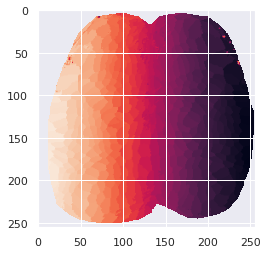

In [17]:
with h5py.File(step_0_root+mouse+'/idx_sorted_500_'+mouse+'.mat','r') as f_idx:
    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
    
    mask = IDX_sorted >0
    mask = mask.astype(float)
    mask[mask==0]='nan'
    
plt.imshow(IDX_sorted)

In [18]:
M2_ind = load_pickle(fetch_path_M2+'brightest_frontline_ind-'+mouse)
sensory_ind = load_pickle(fetch_path_S1+'inferred_brightest_ind_'+mouse)


In [19]:
M_raw={}
t1 = 340
with h5py.File(step_1_root+'{}/{}/{}_stim_1.mat'.format(mouse,'1','runB'),'r') as f_H: 
    for key in ['green','lime','red']:
        C = np.array(f_H['C'][key])
        S = np.array(f_H['S'][key])[t1:t1+1,:]
        CS = np.dot(S,C).transpose()

        temp = CS
        temp = temp.reshape((256,256,-1)).transpose((1,0,2))     

        # temp_norm = temp-np.mean(temp[:,:,bsl],axis=-1)[:,:,np.newaxis]
        M_raw[key] = temp


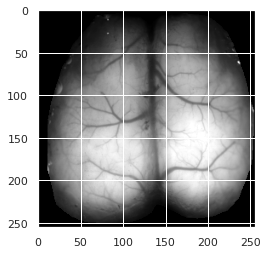

In [20]:
masked_brain = np.multiply(np.squeeze(M_raw['lime']),mask)
masked_brain=np.nan_to_num(masked_brain,0)
plt.imshow(masked_brain,cmap='gray',vmin=500,vmax=4500)

In [21]:

palatte_dict = load_pickle(figure_config_root+'palatte_dict')
# for S1 homunculus
palatte_dict['mouth']=palatte_dict['RM']
palatte_dict['nose']=palatte_dict['RN']
palatte_dict['LV'] = '#ee8c7d'
palatte_dict['tail'] = 'palegreen'
palatte_dict['mouth_M2']='#bf8fc9'
palatte_dict['RFP_M2']='#6dae96'
palatte_dict['RFP_M1']='#4b0082'
palatte_dict['LatM']=palatte_dict['ALM']

In [22]:
# (137,130) #bregma location
pixels_per_mm = 29
x_axis = np.divide(np.linspace(-135,256-135-1,256),pixels_per_mm)
y_axis = np.divide(np.linspace(256-130-1,-130,256),pixels_per_mm)
extent = [x_axis[0],x_axis[-1],y_axis[-1],y_axis[0]]


**load data**

In [23]:
get_path = str(FIGURES / "figure2") + "/"
filename=get_path+'figure2_single_trial_example_cm125_2_runJ.pickle'
save_dict = load_pickle(filename)
print('loading:',save_dict.keys())
for key in save_dict:
    exec("{} = save_dict[key]".format(key))
all_moseq_tc['is_whisking'] = all_bev_tc['whisk_vel_norm'] >0.05

loading: dict_keys(['choice_dict', 'choice_body_part_dict', 'H_dict', 'full_data_dict', 'all_bev_tc', 'all_moseq_tc', 'all_bev_short_dict', 'run_id'])


In [25]:
# RE-ORDER
choice_body_part_dict = {0:'RHP',1:'RFP',2:'RW',3:'RV',
                         4:'RM_M2',5:'RFP_M2',6:'LatM'}
choice_dict = {0:316,1:400,2:sensory_ind['RW'],3:406,4:[],5:[],6:418}



In [26]:
dict_seed_ROI_xy_mice  = load_pickle(figure_config_root+'dict_seed_ROI_xy_mice')

list_choice_M2_l_n_r = ['RFP','RM','RW','RHP','LFP','LM','LW','LHP']
seed_ROI_xy = dict_seed_ROI_xy_mice[mouse]

jrgeco2plot_M2 = {};node_coords_M2 = {}
for i_bdp in range(8):
    bdp = list_choice_M2_l_n_r[i_bdp]
    y_top_left = seed_ROI_xy[bdp]['y_top_left']
    y_botton_right = seed_ROI_xy[bdp]['y_botton_right']
    x_top_left =seed_ROI_xy[bdp]['x_top_left']
    x_botton_right=seed_ROI_xy[bdp]['x_botton_right']
    node_coords_M2[bdp] = np.array([(y_top_left+y_botton_right)/2,(x_top_left+x_botton_right)/2])
    small_roi_tcs = np.nanmean(np.nanmean(
        full_data_dict['jrgeco'][x_top_left:x_botton_right,y_top_left:y_botton_right],0),0)
    jrgeco2plot_M2[bdp] = small_roi_tcs
    
H_jrgeco=getH(full_data_dict['jrgeco'],IDX_sorted)

In [13]:
# # Save to .mat file using HDF5 (MATLAB v7.3 format)
# with h5py.File("jrgeco.mat", "w") as f:
#     f.create_dataset("jrgeco", data=full_data_dict['jrgeco'][:,:,5800:6000])

# print("File saved successfully!")

In [27]:
jrgeco2plot ={}
for i_bdp in range(7):
    bdp = choice_body_part_dict[i_bdp]
    ind = choice_dict[i_bdp]
    if len(bdp.split('_'))==1:
        jrgeco2plot[bdp]=H_jrgeco[ind,:]
    else:
        if bdp.split('_')[1] == 'M2':
            jrgeco2plot[bdp] = jrgeco2plot_M2[bdp.split('_')[0]]         

            

In [28]:
behavior_colors = ['#E64B35', '#4DBBD5', '#00A087', '#3C5488',
                  '#F39B7F', '#8491B4', '#91D1C2FF','#7E6148','#B09C85', '#DC0000'
                   ]

In [29]:
col_list = ["grey"] +  ["dark magenta"] + ["emerald green"] + ["golden rod"] + ["tomato"] + ["marine blue"] +["medium blue"]
col_list_palette = sns.xkcd_palette(col_list)

In [44]:
import matplotlib
col_list_palette = load_pickle(figure_config_root+'col_list_palette')
# palatte_behavior_fig7_dict = load_pickle(figure_config_root+'palatte_behavior_fig7_dict')
palatte_moseq_dict = load_pickle(figure_config_root+'palatte_moseq_dict')

cmap = plt.cm.get_cmap('BuPu', 17)
palatte_3 = [matplotlib.colors.rgb2hex(cmap(i)[:3]) for i in range(cmap.N)]

In [45]:
palatte_moseq_dict

{'is_running': '#01386A',
 'is_integrated': '#2C6FBB',
 'is_rest': '#F9BC08',
 'is_licking_paw': '#EF4026',
 'is_licking_spout': '#df2f2b',
 'is_rise': '#028F1E',
 'is_whisking': '#929591'}

In [46]:
palatte_moseq_dict['is_whisking']=palatte_moseq_dict['is_licking_paw']
palatte_moseq_dict['is_rest']='khaki'
palatte_moseq_dict['is_running'] = 'teal'
all_bev_short_dict['face_pc'] = 'face PC'
all_bev_short_dict['body_pc'] = 'body PC'

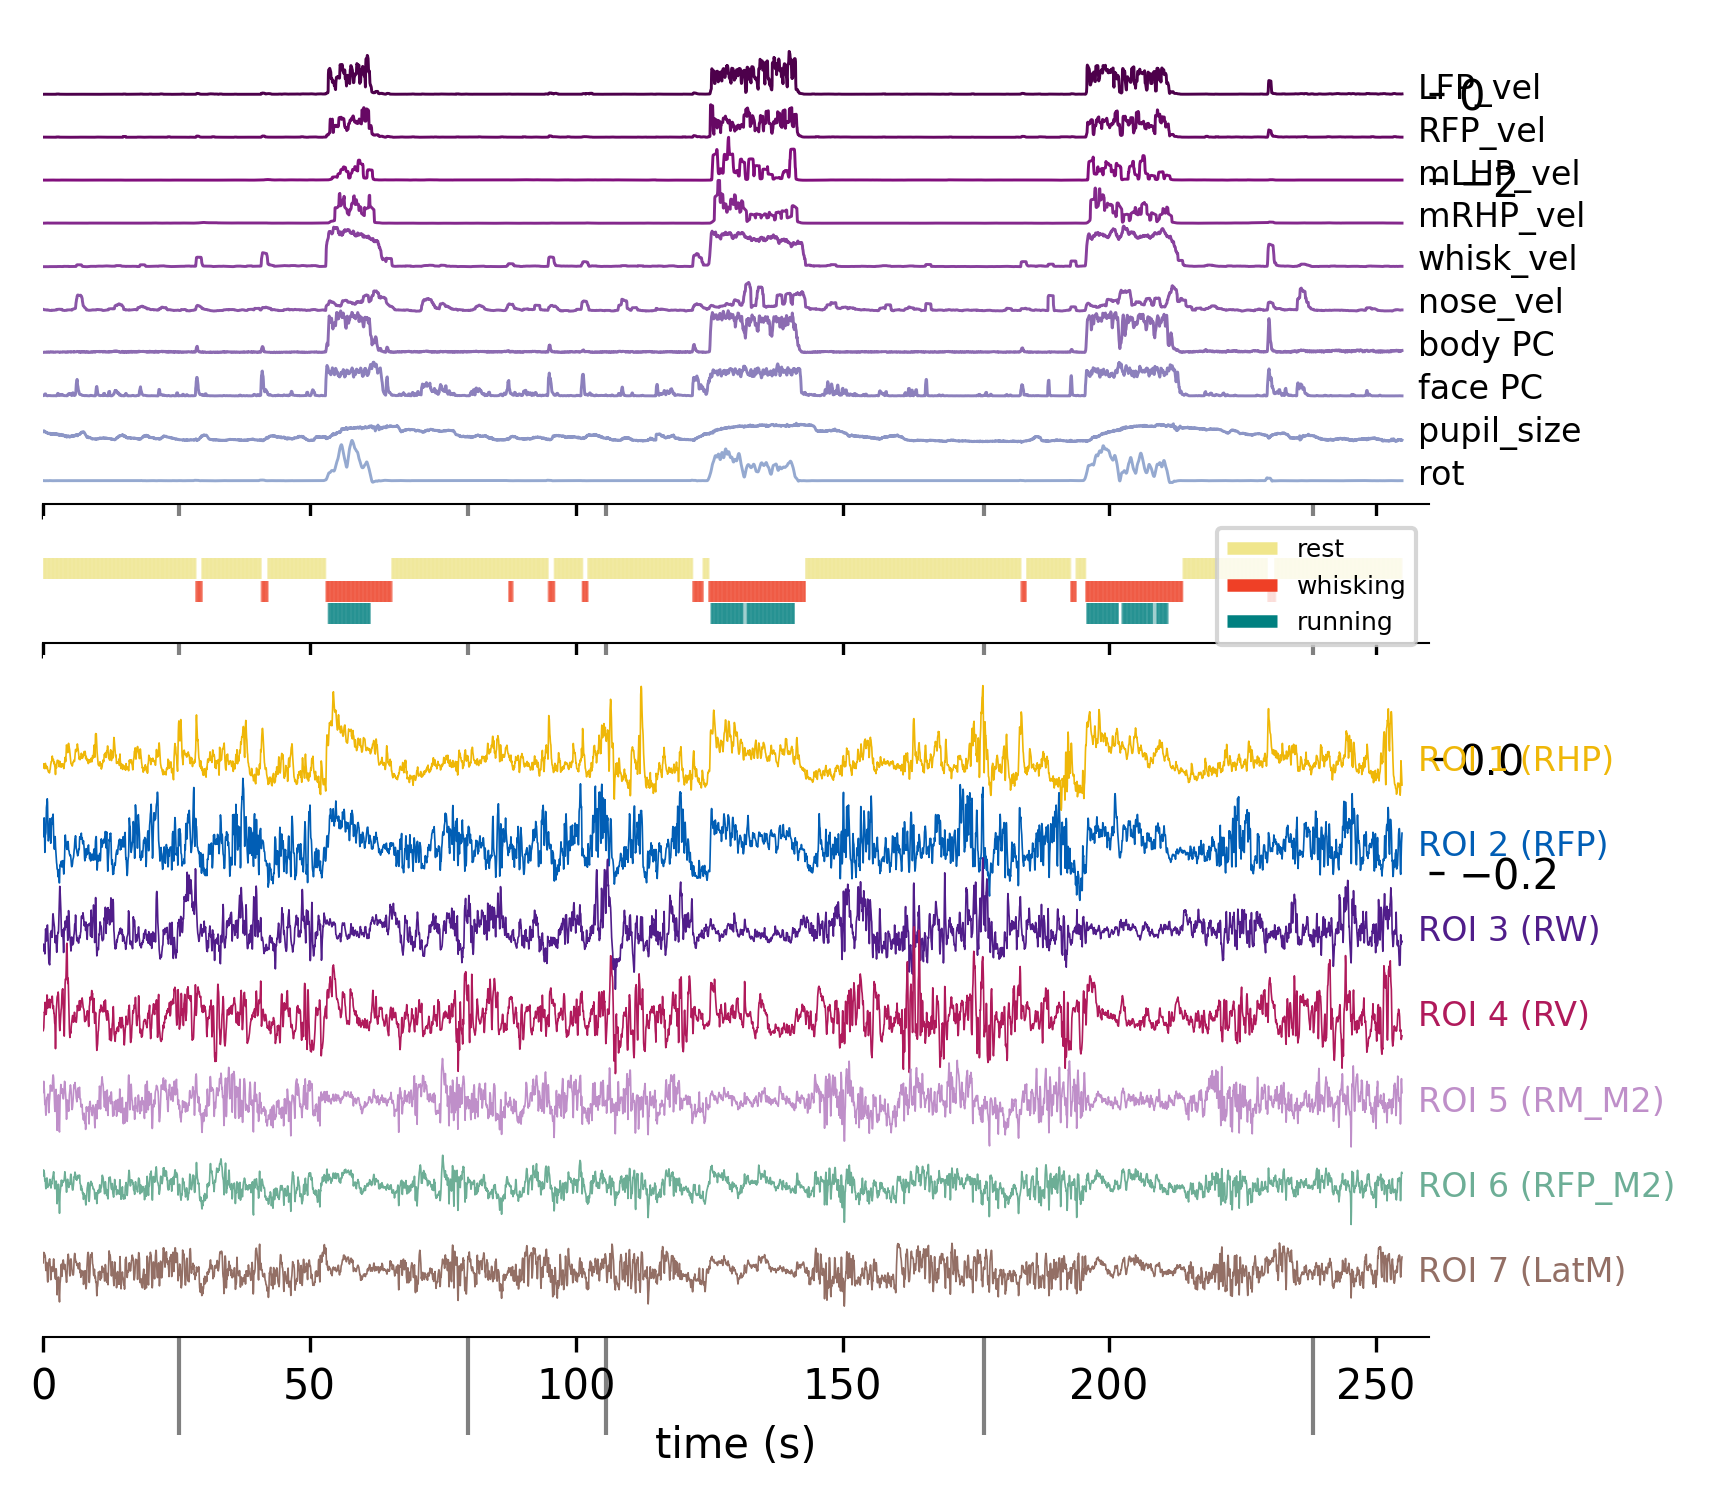

In [ ]:
t1,t2,t3,t4,t5 = 508 ,1595,2110, 3531, 4765
time_series = np.array([t1,t2,t3,t4,t5])


t_tc = np.divide(range(all_bev_tc['whisk_vel_norm'].shape[0]),20) 

from matplotlib.gridspec import GridSpec
from skimage import measure
from matplotlib import ticker
import matplotlib

plt.style.use('default')
gs = GridSpec(100,100)

plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;
x_width=20;

x_start = x_offset
x_stop = x_start+x_width
ax0 = fig.add_subplot(gs[y_offset-3:y_offset+4,x_start:x_stop])
ax1 = fig.add_subplot(gs[y_offset+4:y_offset+6,x_start:x_stop])
ax2 = fig.add_subplot(gs[y_offset+6:y_offset+16,x_start:x_stop])
# ax2 = fig.add_subplot(gs[y_offset+12:y_offset+15,x_start:x_stop])



bev_w_order = ['LFP_vel_norm','RFP_vel_norm','mirrorLHP_vel_norm','mirrorRHP_vel_norm',
               'whisk_vel_norm',
               'nose_vel_norm','body_pc','face_pc','pupil_pc_norm','rot_raw']

for i_beh,beh in enumerate(bev_w_order):
    ax0.plot(t_tc,all_bev_tc[beh]-i_beh*1,linewidth=0.7,color=palatte_3[-i_beh-1],
             label=all_bev_short_dict[beh])
    ax0.text(t_tc[-1]-t_tc[0]+3,-i_beh*1-0.1,all_bev_short_dict[beh],color='black',fontsize=8)
    

# moseq
moseq_list = ['is_rest','is_whisking','is_running']
for i, moseq in enumerate(moseq_list):
    ax1.vlines(t_tc[np.where(all_moseq_tc[moseq]==True)], -8.5-i*0.53, -8-i*0.53,linewidth=0.1,color=palatte_moseq_dict[moseq])
    ax1.vlines(0, 8, 9,linewidth=3,color=palatte_moseq_dict[moseq],label=moseq[3:])#for the legend


for i_bdp in range(7):
    bdp = choice_body_part_dict[i_bdp]
    data_2_plot = jrgeco2plot[bdp]
    ax2.plot(t_tc,data_2_plot-0.15*i_bdp,label=bdp,linewidth=0.4,color=palatte_dict[bdp])
    ax2.text(t_tc[-1]-t_tc[0]+3,-0.15*i_bdp-0.02,'ROI {} ({}) '.format(i_bdp+1,bdp),color=palatte_dict[bdp],fontsize=8)

 

for axis in ['top','right','left','bottom']:
    for i_ax in range(0,3):
        exec("ax{}.spines[axis].set_linewidth(0.5)".format(i_ax))
for axis in ['top','right','left']:
    for i_ax in range(0,3):
        exec("ax{}.spines[axis].set_linewidth(0)".format(i_ax))
        exec("ax{}.yaxis.tick_right()".format(i_ax))
            
# ax1.set_yticks([]);ax2.set_yticks([]);ax3.set_yticks([])
# ax1.set_xticks([]);ax0.set_xticks([])
ax2.set_xlabel('time (s)')
for i_ax,ax in enumerate(['0','1','2']):
    exec("ax{}.set_xlim([0,260])".format(ax))
    
    

for i_t in range(5):
    fig.patches.extend([patches.Polygon([(t_tc[time_series[i_t]],-1.19),(t_tc[time_series[i_t]],1)],
                                      fill=True, color='gray', alpha=1, zorder=-1000,
                                      transform=ax2.transData,
                                      figure=fig)])
    
ax1.legend(fontsize=6)
ax1.set_ylim([-10,-7])
ax1.set_yticks([])
ax0.set_yticks([-2,0])
ax2.set_yticks([-0.2,0])
ax0.set_xticklabels([])
ax1.set_xticklabels([])


    
    
    
plt.savefig('figS1-single-trial-tc.svg',format='svg',dpi=300)

# snapshots

In [364]:
time_range = range(1024,1204)
bsl_range = range(1024,1054)

In [365]:
jrgeco_snippet = full_data_dict['jrgeco'][
    :,:,time_range] - np.mean(
    full_data_dict['jrgeco'][:,:,bsl_range],-1)[:,:,np.newaxis]

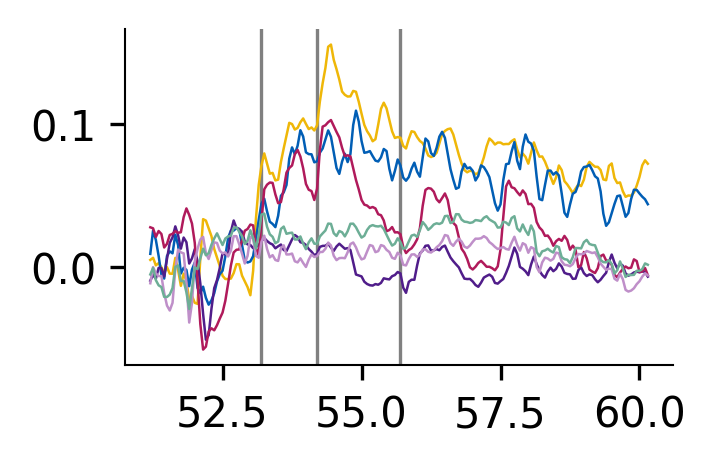

In [ ]:
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;
x_width=8;

x_start = x_offset
x_stop = x_start+x_width
ax0 = fig.add_subplot(gs[y_offset:y_offset+5,x_start:x_stop])


for i_bdp in range(6):
    bdp = choice_body_part_dict[i_bdp]
    data_2_plot = jrgeco2plot[bdp]
    tc_dbsl = data_2_plot[time_range] - np.mean(data_2_plot[bsl_range])
    ax0.plot(t_tc[time_range],tc_dbsl,label=bdp,linewidth=0.6,color=palatte_dict[bdp])

for axis in ['top','right','left','bottom']:
    for i_ax in range(0,3):
        exec("ax{}.spines[axis].set_linewidth(0.5)".format(i_ax))
for axis in ['top','right',]:
    for i_ax in range(0,1):
        exec("ax{}.spines[axis].set_linewidth(0)".format(i_ax))
        
ax1.set_xticklabels([])
ax2.set_xticks([]);ax2.set_yticks([])

ax0.axvline(t_tc[time_range[0]+40],linewidth=0.8,zorder=-500,color='gray')
ax0.axvline(t_tc[time_range[0]+60],linewidth=0.8,zorder=-500,color='gray')  
ax0.axvline(t_tc[time_range[0]+90],linewidth=0.8,zorder=-500,color='gray')  
plt.savefig('figS1-zoom-in-time_range_1024_1204.svg',format='svg',dpi=300)

In [410]:
select_time_points = [40,60,90]
select_jrgeco_maps = []
select_webcam_image_fused = []
for i_t, tp in enumerate(select_time_points):
    select_jrgeco_maps.append(jrgeco_snippet[:,:,tp])
    ind_before = 3*(2200+500+1024+tp-3)
    ind_after = 3*(2200+500+1024+tp+3)
    img_fname_before = webcam_root+'{}/webcam/{}/*{}*cam1*'.format(day_name,run_name,int(ind_before))
    img_fname_after = webcam_root+'{}/webcam/{}/*{}*cam1*'.format(day_name,run_name,int(ind_after))
    import imageio
    f1 = [f for f in glob.glob(img_fname_before, recursive=True)][0]
    image_before = imageio.imread(f1)
    f1 = [f for f in glob.glob(img_fname_after, recursive=True)][0]
    image_after = imageio.imread(f1)
    import cv2
    C = np.dstack((image_before,image_after,image_before))
    im_compare_2_show = C[72*3:,:,:]
    select_webcam_image_fused.append(im_compare_2_show)

/home/wx2203/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:13: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  del sys.path[0]
/home/wx2203/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:15: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  from ipykernel import kernelapp as app


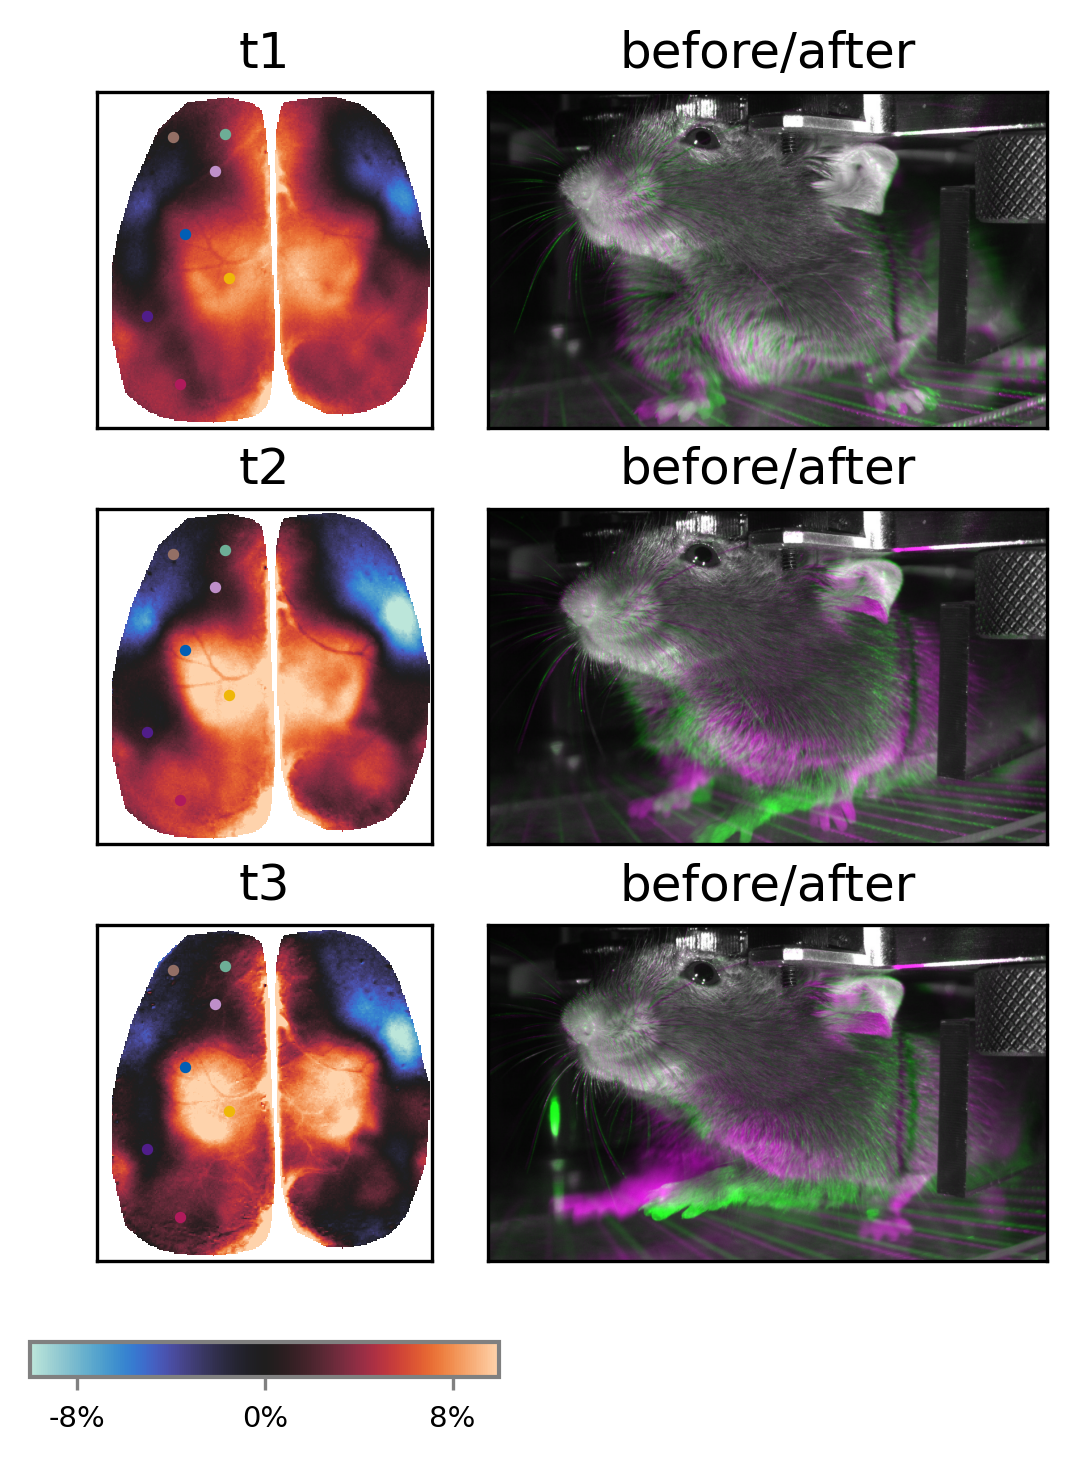

In [ ]:
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;
x_width = 5; y_width = 5; y_gap = 1

x_start = x_offset
x_stop = x_start + x_width
y_start = y_offset
y_stop = y_start + y_width
for i_ax in range(3):
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    y_start = y_start + 5 + y_gap
    y_stop = y_start + y_width
    exec("ax{}.set_yticks([])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))
# colorbar
ax99 = fig.add_subplot(gs[y_start:y_start+1,x_start+1:x_stop-1])

x_start = x_offset + 6
x_stop = x_start + 8
y_start = y_offset
y_stop = y_start + y_width
for i_ax in range(3,6):
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    y_start = y_start + 5 + y_gap
    y_stop = y_start + y_width
    exec("ax{}.set_yticks([])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))
    
#################################################################################
for i_ax in range(3):
    exec("sbp = ax{}.imshow(select_jrgeco_maps[i_ax],vmin=-0.1,vmax=0.1,cmap='icefire')".format(i_ax))
    exec("ax{}.set_title('t{}')".format(i_ax,i_ax+1))
    for i_bdp,bdp_ind in enumerate(choice_body_part_dict):
        ind = choice_dict[i_bdp]
        bdp = choice_body_part_dict[bdp_ind]
        if len(bdp.split('_'))==1:
            exec("ax{}.scatter(node_coords[ind,1],node_coords[ind,0],s=3,color=palatte_dict[bdp])".format(i_ax))
        else:
            if bdp.split('_')[1] == 'M2':
                exec("ax{}.scatter(node_coords_M2[bdp.split('_')[0]][0], node_coords_M2[bdp.split('_')[0]][1], s=3, c=palatte_dict[bdp], zorder=2)".format(i_ax))
            else:
                exec("ax{}.scatter(node_coords[ind,1],node_coords[ind,0],s=3,color=palatte_dict[bdp])".format(i_ax))
       

for i_count, i_ax in enumerate(range(3,6)):
    exec("ax{}.imshow(select_webcam_image_fused[i_count])".format(i_ax))
    exec("ax{}.set_title('before/after')".format(i_ax))
    
plt.subplots_adjust(wspace=-0.8)
################################################################################
cb = fig.colorbar(sbp, cax=ax99,orientation='horizontal',format=FuncFormatter(fmt));
cb.ax.tick_params(labelsize=7,length=3,color='gray')
cb.ax.yaxis.tick_right()       
cb.outline.set_edgecolor('gray')
cb.outline.set_linewidth(1)
tick_locator = ticker.MaxNLocator(nbins=3)
cb.locator = tick_locator
cb.update_ticks()
ax99.set_aspect(0.015)
ax99.set_anchor('N')




plt.savefig('figS1-snapshot-t1-t2-t3.svg',format='svg',dpi=300)